# 02.02. IPCA — Análise por Subgrupos



## Hierarquia • Variação • Peso • Contribuição • Impacto • Difusão

Este notebook aprofunda a decomposição do IPCA iniciada em:

```text
02.ipca
    |
    v
IPCA geral

02.01.grupos
    |
    v
grandes componentes

02.02.subgrupos
    |
    v
decomposição interna dos grupos
```

O notebook assume que:

- os pipelines já foram executados;
- `bcb.ipca_subgrupos` está atualizada;
- `bcb.ipca_grupos` está atualizada;
- a auditoria dos dados foi concluída.

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.

---


### Objetivos

1. Entender a posição dos subgrupos na hierarquia do IPCA.
2. Relacionar cada subgrupo ao seu grupo-pai.
3. Examinar variação e peso dos subgrupos.
4. Calcular contribuição e impacto.
5. Identificar as principais pressões inflacionárias.
6. Analisar a composição interna dos grupos.
7. Verificar a consistência entre subgrupos e grupos.
8. Medir a difusão da inflação.
9. Preparar representações para análises e modelagem posteriores.

### 1. Hierarquia do IPCA

Neste projeto utilizamos:

```text
grupo      -> código de 1 dígito
subgrupo   -> código de 2 dígitos
item       -> código de 4 dígitos
subitem    -> código de 7 dígitos
```

Exemplo conceitual:

```text
grupo
  |
  +-- subgrupo
  |      |
  |      +-- item
  |             |
  |             +-- subitem
  |
  +-- subgrupo
```

Como o código do grupo está contido no início do código do subgrupo,
podemos utilizar o primeiro dígito do subgrupo para identificar
seu grupo-pai.

### 2. O que o subgrupo acrescenta?

O notebook anterior respondeu:

> Quais grandes grupos explicaram a inflação?

Neste nível aprofundamos a pergunta:

> Quais componentes internos explicaram o comportamento desses grupos?

Conceitualmente:

```text
IPCA geral
     |
     v
   grupo
     |
     +-- subgrupo A
     +-- subgrupo B
     +-- subgrupo C
```

Isso permite localizar com maior precisão as fontes da inflação sem
alcançar ainda a granularidade muito elevada de itens e subitens.

### 3. Quatro conceitos fundamentais

Utilizaremos:

* indice $\to\qquad$ variação dos preços
* peso $\to\qquad$ importância relativa
* contribuicao $\to\qquad$ efeito com sinal sobre o IPCA
* impacto $\to\qquad$ magnitude da contribuição


#### 3.1 Variação

Seja $\pi_{i,t}$ a variação mensal dos preços do subgrupo $i$
no período $t$.

A variável `indice` representa essa variação em percentual.

Por exemplo, $\pi_{i,t} = 1{,}20$ representa uma variação mensal
de $1{,}20\%$.

#### 3.2 Peso

Seja $w_{i,t}$ o peso publicado para o subgrupo $i$ no período $t$.

O peso representa a importância relativa daquele componente na
estrutura do índice.

Um movimento elevado de preços em um componente com peso muito pequeno
pode produzir efeito menor sobre o IPCA do que um movimento moderado
em um componente de peso elevado.

#### 3.3 Contribuição

Para nossa decomposição analítica utilizamos:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

onde:

- $\pi_{i,t}$ é a variação mensal do subgrupo;
- $w_{i,t}$ é o peso publicado;
- $C_{i,t}$ é a contribuição aproximada em pontos percentuais.

A contribuição mantém o sinal:

$$
C_{i,t} > 0 \quad\Rightarrow\quad \text{contribuição positiva}
$$

$$
C_{i,t} < 0 \quad\Rightarrow\quad \text{contribuição negativa}
$$

Portanto, utilizaremos `contribuicao` principalmente quando a direção
do efeito for relevante.

#### 3.4 Impacto

Quando a pergunta for:

> Qual componente exerceu maior pressão ou teve maior relevância
> para o movimento da inflação?

interessa a magnitude da contribuição, independentemente da direção.

Definimos:

$$
I_{i,t}=\left| C_{i,t} \right|
$$

onde $I_{i,t}$ representa o impacto absoluto do subgrupo.

Exemplo:

| Subgrupo | Contribuição | Impacto |
|---|---:|---:|
| A | $+0{,}30$ p.p. | $0{,}30$ p.p. |
| B | $-0{,}45$ p.p. | $0{,}45$ p.p. |
| C | $+0{,}20$ p.p. | $0{,}20$ p.p. |

O subgrupo B apresentou a maior pressão em magnitude sobre o movimento
do IPCA, apesar de sua contribuição ter ocorrido na direção negativa.

### 4. Configuração do ambiente

In [84]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 5. Importações

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 150)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.4f}".format)

### 6. Carregar subgrupos do PostgreSQL

In [86]:
subgrupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subgrupos
    ORDER BY date, categoria;
    """,
    engine,
)

#### 6.1 Preparar os dados

In [87]:
subgrupos["date"] = pd.to_datetime(
    subgrupos["date"]
)

subgrupos["categoria"] = (
    subgrupos["categoria"]
    .astype(str)
)

subgrupos = (
    subgrupos
    .sort_values(
        ["date", "categoria"]
    )
    .reset_index(drop=True)
)

#### 6.2 Identificar o grupo-pai

In [88]:
subgrupos["grupo_codigo"] = (
    subgrupos["categoria"]
    .str[:1]
)

#### 6.3 Calcular contribuição e impacto

In [89]:
subgrupos["contribuicao"] = (
    subgrupos["indice"]
    * subgrupos["peso"]
    / 100
)

subgrupos["impacto"] = (
    subgrupos["contribuicao"]
    .abs()
)

#### 6.4 Direção da contribuição

In [90]:
subgrupos["direcao"] = np.select(
    [
        subgrupos["contribuicao"] > 0,
        subgrupos["contribuicao"] < 0,
    ],
    [
        "positiva",
        "negativa",
    ],
    default="neutra",
)

subgrupos.head(10)

,date,categoria,categoria_nome,indice,peso,grupo_codigo,contribuicao,impacto,direcao
0,2020-01-01,11,Alimentação no domicílio,0.2000,13.4813,1,0.0270,0.0270,positiva
1,2020-01-01,12,Alimentação fora do domicílio,0.8200,5.8670,1,0.0481,0.0481,positiva
2,2020-01-01,21,Encargos e manutenção,0.6800,9.9808,2,0.0679,0.0679,positiva
3,2020-01-01,22,Combustíveis e energia,0.3100,5.6138,2,0.0174,0.0174,positiva
4,2020-01-01,31,Móveis e utensílios,-0.1900,1.7949,3,-0.0034,0.0034,negativa
5,2020-01-01,32,Aparelhos eletroeletrônicos,0.0200,1.6432,3,0.0003,0.0003,positiva
6,2020-01-01,33,Consertos e manutenção,0.1500,0.3147,3,0.0005,0.0005,positiva
7,2020-01-01,41,Roupas,-0.6400,3.1247,4,-0.0200,0.0200,negativa
8,2020-01-01,42,Calçados e acessórios,-0.2600,1.1975,4,-0.0031,0.0031,negativa
9,2020-01-01,43,Joias e bijuterias,0.6900,0.1996,4,0.0014,0.0014,positiva


### 7. Carregar referência dos grupos

In [91]:
grupos_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_grupos
    ORDER BY categoria;
    """,
    engine,
)

grupos_ref["categoria"] = (
    grupos_ref["categoria"]
    .astype(str)
)

grupos_ref = (
    grupos_ref
    .rename(
        columns={
            "categoria": "grupo_codigo",
            "categoria_nome": "grupo_nome",
        }
    )
)

#### 7.1 Associar grupo-pai ao subgrupo

In [92]:
subgrupos = (
    subgrupos
    .merge(
        grupos_ref,
        on="grupo_codigo",
        how="left",
        validate="many_to_one",
    )
)

subgrupos[
    [
        "categoria",
        "categoria_nome",
        "grupo_codigo",
        "grupo_nome",
    ]
].drop_duplicates().head(30)

,categoria,categoria_nome,grupo_codigo,grupo_nome
0,11,Alimentação no domicílio,1,Alimentação e bebidas
1,12,Alimentação fora do domicílio,1,Alimentação e bebidas
2,21,Encargos e manutenção,2,Habitação
3,22,Combustíveis e energia,2,Habitação
4,31,Móveis e utensílios,3,Artigos de residência
5,32,Aparelhos eletroeletrônicos,3,Artigos de residência
6,33,Consertos e manutenção,3,Artigos de residência
7,41,Roupas,4,Vestuário
8,42,Calçados e acessórios,4,Vestuário
9,43,Joias e bijuterias,4,Vestuário


### 8. Cobertura histórica

In [93]:
resumo = pd.DataFrame(
    [
        {
            "inicio": subgrupos["date"].min(),
            "fim": subgrupos["date"].max(),
            "observacoes": len(subgrupos),
            "subgrupos": subgrupos["categoria"].nunique(),
            "grupos_pai": subgrupos["grupo_codigo"].nunique(),
        }
    ]
)

resumo

,inicio,fim,observacoes,subgrupos,grupos_pai
0,2020-01-01,2026-08-01,1520,19,9


### 9. Catálogo hierárquico

In [94]:
catalogo = (
    subgrupos[
        [
            "grupo_codigo",
            "grupo_nome",
            "categoria",
            "categoria_nome",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "grupo_codigo",
            "categoria",
        ]
    )
    .reset_index(drop=True)
)

catalogo

,grupo_codigo,grupo_nome,categoria,categoria_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio
1,1,Alimentação e bebidas,12,Alimentação fora do domicílio
2,2,Habitação,21,Encargos e manutenção
3,2,Habitação,22,Combustíveis e energia
4,3,Artigos de residência,31,Móveis e utensílios
5,3,Artigos de residência,32,Aparelhos eletroeletrônicos
6,3,Artigos de residência,33,Consertos e manutenção
7,4,Vestuário,41,Roupas
8,4,Vestuário,42,Calçados e acessórios
9,4,Vestuário,43,Joias e bijuterias


### 10. Quantidade de subgrupos por grupo

In [95]:
quantidade_por_grupo = (
    catalogo
    .groupby(
        [
            "grupo_codigo",
            "grupo_nome",
        ]
    )
    .size()
    .rename("subgrupos")
    .reset_index()
    .sort_values(
        "subgrupos",
        ascending=False,
    )
)

quantidade_por_grupo

,grupo_codigo,grupo_nome,subgrupos
3,4,Vestuário,4
5,6,Saúde e cuidados pessoais,3
2,3,Artigos de residência,3
0,1,Alimentação e bebidas,2
1,2,Habitação,2
6,7,Despesas pessoais,2
4,5,Transportes,1
7,8,Educação,1
8,9,Comunicação,1


---

## PARTE I — ÚLTIMO MÊS



### 11. Último mês disponível

In [96]:
ultimo_mes = subgrupos["date"].max()

subgrupos_ultimo = (
    subgrupos[
        subgrupos["date"] == ultimo_mes
    ]
    .copy()
)

print(
    "Último mês disponível:",
    ultimo_mes.strftime("%Y-%m"),
)

Último mês disponível: 2026-08


### 12. Subgrupos com maior peso

Esta visão responde:

> Quais subgrupos possuem maior importância relativa na estrutura
> atual do IPCA?

In [97]:
subgrupos_ultimo[
    [
        "grupo_nome",
        "categoria_nome",
        "peso",
    ]
].sort_values(
    "peso",
    ascending=False,
).head(20)

,grupo_nome,categoria_nome,peso
1512,Transportes,Transportes,20.2696
1501,Alimentação e bebidas,Alimentação no domicílio,15.4239
1503,Habitação,Encargos e manutenção,9.8164
1516,Despesas pessoais,Serviços pessoais,6.3498
1518,Educação,"Cursos, leitura e papelaria",6.1601
1502,Alimentação e bebidas,Alimentação fora do domicílio,6.0877
1514,Saúde e cuidados pessoais,Serviços de saúde,5.9532
1504,Habitação,Combustíveis e energia,5.6866
1519,Comunicação,Comunicação,4.5011
1515,Saúde e cuidados pessoais,Cuidados pessoais,4.1025


### 13. Maiores variações positivas

Esta análise considera somente a magnitude da variação dos preços,
sem considerar ainda o peso do componente.

In [98]:
subgrupos_ultimo[
    [
        "grupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nlargest(
    15,
    "indice",
)

,grupo_nome,categoria_nome,indice,peso,contribuicao,impacto
1517,Despesas pessoais,Recreação e fumo,2.8100,3.8929,0.1094,0.1094
1506,Artigos de residência,Aparelhos eletroeletrônicos,1.1200,1.3885,0.0156,0.0156
1509,Vestuário,Calçados e acessórios,0.7500,1.2178,0.0091,0.0091
1518,Educação,"Cursos, leitura e papelaria",0.4700,6.1601,0.0290,0.0290
1505,Artigos de residência,Móveis e utensílios,0.3900,1.7149,0.0067,0.0067
1514,Saúde e cuidados pessoais,Serviços de saúde,0.3800,5.9532,0.0226,0.0226
1503,Habitação,Encargos e manutenção,0.3700,9.8164,0.0363,0.0363
1516,Despesas pessoais,Serviços pessoais,0.3700,6.3498,0.0235,0.0235
1502,Alimentação e bebidas,Alimentação fora do domicílio,0.3600,6.0877,0.0219,0.0219
1513,Saúde e cuidados pessoais,Produtos farmacêuticos e óticos,0.3000,3.7091,0.0111,0.0111


### 14. Maiores variações negativas

In [99]:
subgrupos_ultimo[
    [
        "grupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nsmallest(
    15,
    "indice",
)

,grupo_nome,categoria_nome,indice,peso,contribuicao,impacto
1504,Habitação,Combustíveis e energia,-5.7400,5.6866,-0.3264,0.3264
1512,Transportes,Transportes,-0.8600,20.2696,-0.1743,0.1743
1501,Alimentação e bebidas,Alimentação no domicílio,-0.6100,15.4239,-0.0941,0.0941
1511,Vestuário,Tecidos e armarinho,-0.1700,0.0507,-0.0001,0.0001
1510,Vestuário,Joias e bijuterias,-0.1500,0.2798,-0.0004,0.0004
1508,Vestuário,Roupas,-0.1000,3.0480,-0.0030,0.0030
1519,Comunicação,Comunicação,-0.0900,4.5011,-0.0041,0.0041
1515,Saúde e cuidados pessoais,Cuidados pessoais,-0.0400,4.1025,-0.0016,0.0016
1507,Artigos de residência,Consertos e manutenção,0.0100,0.3476,0.0000,0.0000
1513,Saúde e cuidados pessoais,Produtos farmacêuticos e óticos,0.3000,3.7091,0.0111,0.0111


### 15. Principais pressões sobre o IPCA

Quando queremos identificar quais componentes foram mais relevantes
para o movimento do IPCA, utilizamos `impacto`.

Assim, contribuições positivas e negativas concorrem no mesmo ranking
pela magnitude:

$$
I_{i,t}=|C_{i,t}|
$$

In [100]:
ranking_impacto = (
    subgrupos_ultimo[
        [
            "grupo_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ]
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
    .reset_index(drop=True)
)

ranking_impacto.head(20)

,grupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
0,Habitação,Combustíveis e energia,-5.7400,5.6866,-0.3264,0.3264,negativa
1,Transportes,Transportes,-0.8600,20.2696,-0.1743,0.1743,negativa
2,Despesas pessoais,Recreação e fumo,2.8100,3.8929,0.1094,0.1094,positiva
3,Alimentação e bebidas,Alimentação no domicílio,-0.6100,15.4239,-0.0941,0.0941,negativa
4,Habitação,Encargos e manutenção,0.3700,9.8164,0.0363,0.0363,positiva
5,Educação,"Cursos, leitura e papelaria",0.4700,6.1601,0.0290,0.0290,positiva
6,Despesas pessoais,Serviços pessoais,0.3700,6.3498,0.0235,0.0235,positiva
7,Saúde e cuidados pessoais,Serviços de saúde,0.3800,5.9532,0.0226,0.0226,positiva
8,Alimentação e bebidas,Alimentação fora do domicílio,0.3600,6.0877,0.0219,0.0219,positiva
9,Artigos de residência,Aparelhos eletroeletrônicos,1.1200,1.3885,0.0156,0.0156,positiva


### 16. Gráfico das principais pressões

Neste gráfico, o tamanho da barra representa o impacto absoluto.

Portanto, o gráfico responde:

> Quais subgrupos mais movimentaram o IPCA no mês?

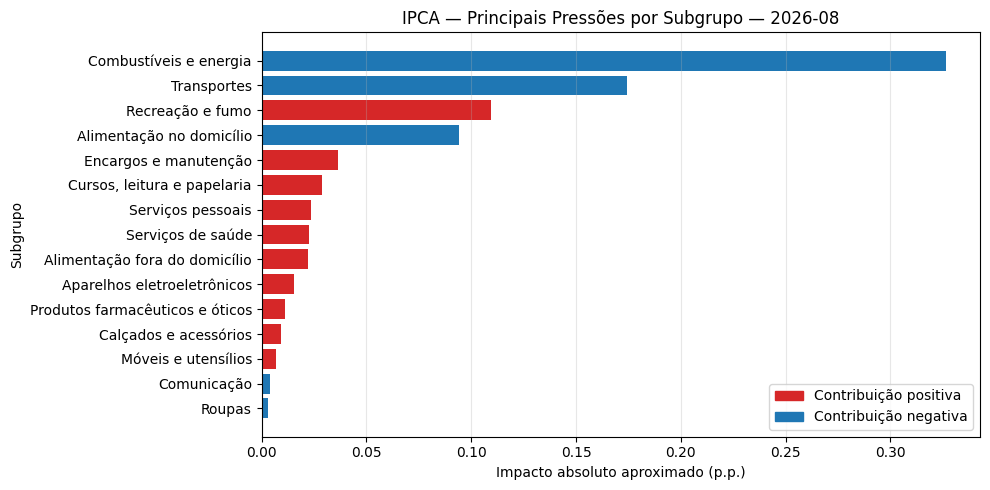

In [123]:
from matplotlib.patches import Patch

top_impacto = (
    ranking_impacto
    .head(15)
    .sort_values("impacto")
)

cores = np.where(
    top_impacto["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_impacto["categoria_nome"],
    top_impacto["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Principais Pressões por Subgrupo — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Impacto absoluto aproximado (p.p.)")
plt.ylabel("Subgrupo")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 17. Direção das principais pressões

O impacto identifica magnitude, mas não preserva a direção.

Por isso, para interpretar os componentes mais relevantes, observamos
novamente suas contribuições com sinal.

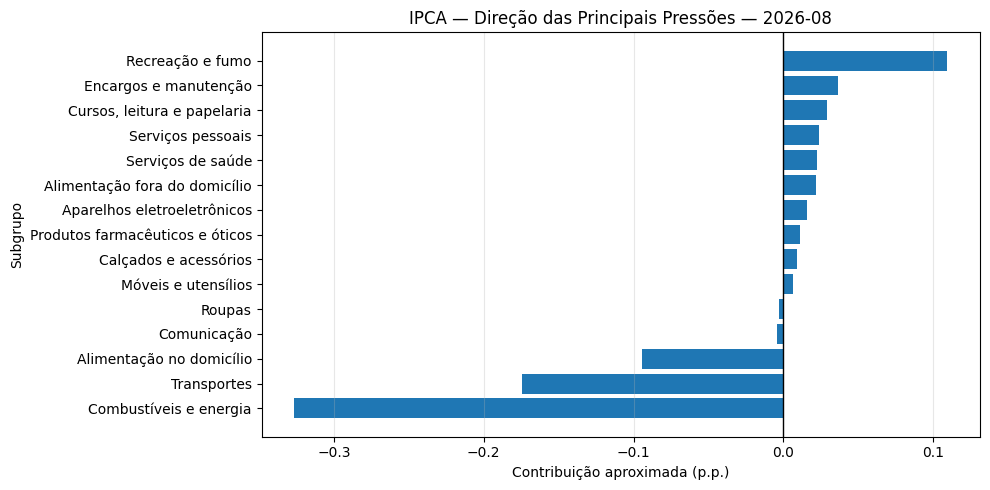

In [102]:
top_pressao_direcao = (
    subgrupos_ultimo
    .sort_values(
        "impacto",
        ascending=False,
    )
    .head(15)
    .sort_values("contribuicao")
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_pressao_direcao["categoria_nome"],
    top_pressao_direcao["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Direção das Principais Pressões — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Subgrupo")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 18. Interpretação conjunta

Os dois gráficos anteriores respondem perguntas complementares.

* **Impacto**

$$
I_{i,t} = |C_{i,t}|
$$

Responde:

> Quem mais movimentou o índice?

* **Contribuição**

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

Responde:

> Em qual direção esse componente movimentou o índice?

Assim:

* impacto $\to\qquad$ magnitude da pressão
* contribuição $\to\qquad$ direção da pressão


---

## PARTE II — COMPOSIÇÃO DENTRO DOS GRUPOS


### 19. Selecionar um grupo

Com mais categorias, não é eficiente colocar todos os subgrupos
simultaneamente em um único gráfico.

A análise hierárquica é mais útil:

```text
selecionar grupo
      |
      v
analisar seus subgrupos
```

In [103]:
grupo_escolhido = (
    grupos_ref
    .sort_values("grupo_codigo")
    .iloc[0]["grupo_nome"]
)

grupo_escolhido

'Alimentação e bebidas'

O grupo pode ser escolhido explicitamente:

```python
grupo_escolhido = "Alimentação e bebidas"
```

In [104]:
subgrupo_selecionado = (
    subgrupos[
        subgrupos["grupo_nome"]
        == grupo_escolhido
    ]
    .copy()
)

subgrupo_selecionado[
    [
        "categoria",
        "categoria_nome",
    ]
].drop_duplicates()

,categoria,categoria_nome
0,11,Alimentação no domicílio
1,12,Alimentação fora do domicílio


### 20. Janela dos últimos 10 anos

In [105]:
data_inicio_10a = (
    subgrupos["date"].max()
    - pd.DateOffset(years=10)
)

grupo_10a = (
    subgrupo_selecionado[
        subgrupo_selecionado["date"]
        >= data_inicio_10a
    ]
    .copy()
)

### 21. Variação mensal dos subgrupos

Utilizamos pequenos múltiplos em vez de sobrepor várias séries
no mesmo gráfico.

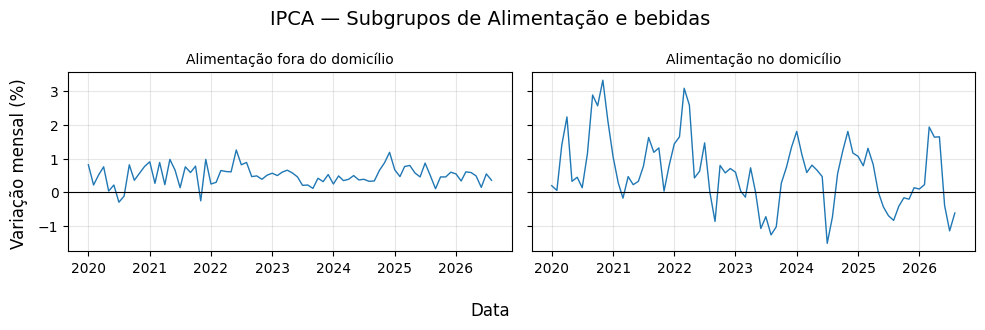

In [106]:
nomes_subgrupos = sorted(
    grupo_10a["categoria_nome"]
    .unique()
)

n = len(nomes_subgrupos)
ncols = 2
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 3.2 * nrows),
    sharex=True,
    sharey=True,
)

axes = np.atleast_1d(
    axes
).flatten()

for ax, nome in zip(
    axes,
    nomes_subgrupos,
):
    dados = grupo_10a[
        grupo_10a["categoria_nome"]
        == nome
    ]

    ax.plot(
        dados["date"],
        dados["indice"],
        linewidth=1,
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.set_title(
        nome,
        fontsize=10,
    )

    ax.grid(
        True,
        alpha=0.3,
    )

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(
    f"IPCA — Subgrupos de {grupo_escolhido}",
    fontsize=14,
)

fig.supxlabel("Data")
fig.supylabel("Variação mensal (%)")

plt.tight_layout()
plt.show()

### 22. Pressões dentro do grupo selecionado

Para observar quais subgrupos tiveram maior relevância em cada mês,
utilizamos o impacto.

Como:

$$
I_{i,t}=|C_{i,t}|
$$

a análise ignora inicialmente a direção e enfatiza a intensidade
dos movimentos.

Utilizaremos os últimos 36 meses para preservar a legibilidade.

In [107]:
data_inicio_36m = (
    subgrupos["date"].max()
    - pd.DateOffset(months=35)
)

grupo_36m = grupo_10a[
    grupo_10a["date"] >= data_inicio_36m
].copy()

impacto_grupo_36m = (
    grupo_36m
    .pivot(
        index="date",
        columns="categoria_nome",
        values="impacto",
    )
    .fillna(0)
    .sort_index()
)

impacto_grupo_36m.index = (
    impacto_grupo_36m.index
    .strftime("%Y-%m")
)

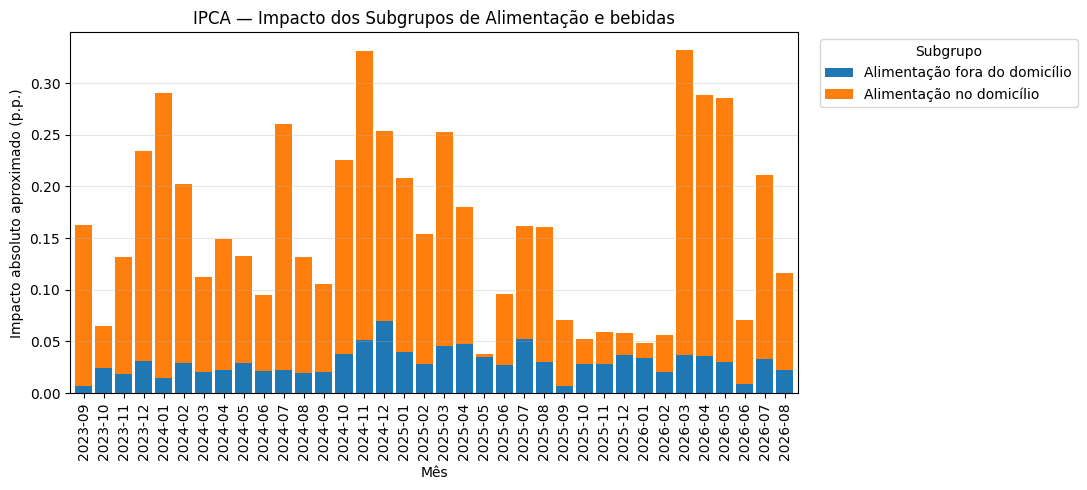

In [108]:
ax = impacto_grupo_36m.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    width=0.85,
)

ax.set_title(
    f"IPCA — Impacto dos Subgrupos de {grupo_escolhido}"
)

ax.set_xlabel("Mês")
ax.set_ylabel(f"Impacto absoluto aproximado (p.p.)")

ax.legend(
    title="Subgrupo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.xticks(
    rotation=90
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

#### Importante

O gráfico de impactos acima NÃO reconstrói a inflação do grupo.

Isso ocorre porque:

$$
\sum_i |C_{i,t}|
\neq
\left|\sum_i C_{i,t}\right|
$$

em geral.

O gráfico mostra a intensidade total das pressões internas.

Para reconstruir o movimento do grupo precisamos preservar os sinais
utilizando `contribuicao`.

### 23. Contribuições dentro do grupo

Agora preservamos a direção das contribuições.

Este gráfico mostra simultaneamente:

- componentes que pressionaram para cima;
- componentes que contribuíram negativamente.

In [109]:
contrib_grupo_36m = (
    grupo_36m
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .fillna(0)
    .sort_index()
)

contrib_grupo_36m.index = (
    contrib_grupo_36m.index
    .strftime("%Y-%m")
)

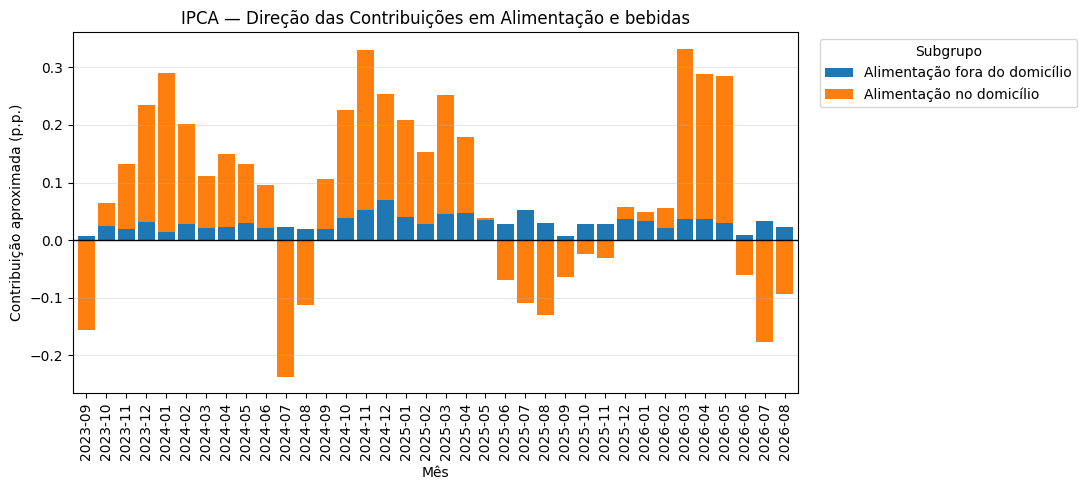

In [110]:
ax = contrib_grupo_36m.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    width=0.85,
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title(
    f"IPCA — Direção das Contribuições em {grupo_escolhido}"
)

ax.set_xlabel("Mês")
ax.set_ylabel("Contribuição aproximada (p.p.)")

ax.legend(
    title="Subgrupo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.xticks(
    rotation=90
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

---

## PARTE III — HEATMAP RECENTE



### 24. Heatmap dos últimos 12 meses

O heatmap permite identificar rapidamente:

- inflação positiva;
- inflação negativa;
- componentes com movimentos intensos;
- persistência dos movimentos.

In [111]:
ultimos_12_meses = (
    subgrupos["date"]
    .drop_duplicates()
    .sort_values()
    .tail(12)
)

subgrupos_12m = subgrupos[
    subgrupos["date"].isin(
        ultimos_12_meses
    )
].copy()

subgrupos_12m["periodo"] = (
    subgrupos_12m["date"]
    .dt.strftime("%Y-%m")
)

pivot_hm = (
    subgrupos_12m
    .pivot(
        index="categoria_nome",
        columns="periodo",
        values="indice",
    )
)

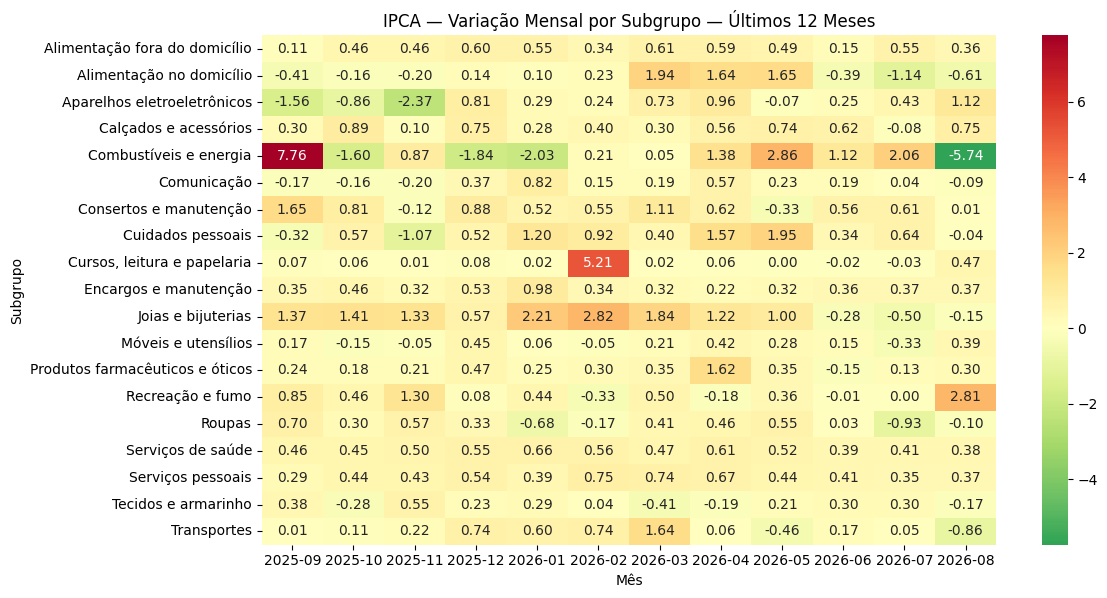

In [112]:
plt.figure(
    figsize=(
        12,
        max(
            6,
            len(pivot_hm) * 0.32,
        ),
    )
)

sns.heatmap(
    pivot_hm,
    cmap="RdYlGn_r",
    center=0,
    annot=True,
    fmt=".2f",
)

plt.title(
    "IPCA — Variação Mensal por Subgrupo — Últimos 12 Meses"
)

plt.xlabel("Mês")
plt.ylabel("Subgrupo")

plt.tight_layout()
plt.show()

---

## PARTE IV — CONSISTÊNCIA COM OS GRUPOS



### 25. Relação hierárquica

Se $g$ representa um grupo e $i \in g$ representa os subgrupos
pertencentes a esse grupo, esperamos aproximadamente:

$$
C_{g,t}
\approx
\sum_{i \in g} C_{i,t}
$$

Essa relação utiliza contribuição, e não impacto, porque a agregação
exige preservar os sinais.

O impacto:

$$
I_{i,t}=|C_{i,t}|
$$

é utilizado para medir relevância e pressão, mas não deve ser somado
para reconstruir o índice.

### 26. Carregar grupos para comparação

In [113]:
grupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_grupos
    ORDER BY date, categoria;
    """,
    engine,
)

grupos["date"] = pd.to_datetime(
    grupos["date"]
)

grupos["categoria"] = (
    grupos["categoria"]
    .astype(str)
)

grupos["contribuicao_grupo"] = (
    grupos["indice"]
    * grupos["peso"]
    / 100
)

### 27. Somar contribuições dos subgrupos

In [114]:
contrib_subgrupos = (
    subgrupos
    .groupby(
        [
            "date",
            "grupo_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_subgrupos"
        }
    )
)

### 28. Comparar grupos e subgrupos

In [115]:
comparacao_hierarquia = (
    grupos[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao_grupo",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "grupo_codigo",
            "categoria_nome":
            "grupo_nome",
        }
    )
    .merge(
        contrib_subgrupos,
        on=[
            "date",
            "grupo_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

comparacao_hierarquia[
    "erro_reconstrucao"
] = (
    comparacao_hierarquia[
        "contribuicao_subgrupos"
    ]
    - comparacao_hierarquia[
        "contribuicao_grupo"
    ]
)

comparacao_hierarquia[
    "erro_abs"
] = (
    comparacao_hierarquia[
        "erro_reconstrucao"
    ]
    .abs()
)

comparacao_hierarquia.tail(20)

,date,grupo_codigo,grupo_nome,contribuicao_grupo,contribuicao_subgrupos,erro_reconstrucao,erro_abs
700,2026-06-01,8,Educação,-0.0012,-0.0012,0.0000,0.0000
701,2026-06-01,9,Comunicação,0.0086,0.0086,0.0000,0.0000
702,2026-07-01,1,Alimentação e bebidas,-0.1452,-0.1446,0.0006,0.0006
703,2026-07-01,2,Habitação,0.1521,0.1511,-0.0010,0.0010
704,2026-07-01,3,Artigos de residência,0.0024,0.0024,-0.0000,0.0000
705,2026-07-01,4,Vestuário,-0.0306,-0.0309,-0.0003,0.0003
706,2026-07-01,5,Transportes,0.0101,0.0101,0.0000,0.0000
707,2026-07-01,6,Saúde e cuidados pessoais,0.0549,0.0552,0.0004,0.0004
708,2026-07-01,7,Despesas pessoais,0.0225,0.0222,-0.0003,0.0003
709,2026-07-01,8,Educação,-0.0019,-0.0019,0.0000,0.0000


### 29. Erro de reconstrução

Definimos:

$$
\varepsilon_{g,t} =\left(\sum_{i \in g} C_{i,t}\right)-C_{g,t}
$$

e o erro absoluto:

$$
|\varepsilon_{g,t}|
$$

Pequenos erros são esperados devido, entre outros fatores, ao
arredondamento das séries disponibilizadas.

In [116]:
comparacao_hierarquia[
    "erro_reconstrucao"
].describe()

count   720.0000
mean     -0.0000
std       0.0004
min      -0.0017
25%      -0.0001
50%       0.0000
75%       0.0001
max       0.0017
Name: erro_reconstrucao, dtype: float64

### 30. Maiores diferenças de reconstrução

In [117]:
comparacao_hierarquia.nlargest(
    20,
    "erro_abs",
)[
    [
        "date",
        "grupo_nome",
        "contribuicao_grupo",
        "contribuicao_subgrupos",
        "erro_reconstrucao",
        "erro_abs",
    ]
]

,date,grupo_nome,contribuicao_grupo,contribuicao_subgrupos,erro_reconstrucao,erro_abs
594,2025-07-01,Alimentação e bebidas,-0.0590,-0.0573,0.0017,0.0017
342,2023-03-01,Alimentação e bebidas,0.0109,0.0125,0.0017,0.0017
585,2025-06-01,Alimentação e bebidas,-0.0395,-0.0411,-0.0017,0.0017
558,2025-03-01,Alimentação e bebidas,0.2543,0.2528,-0.0015,0.0015
117,2021-02-01,Alimentação e bebidas,0.0575,0.0590,0.0015,0.0015
234,2022-03-01,Alimentação e bebidas,0.5054,0.5070,0.0015,0.0015
153,2021-06-01,Alimentação e bebidas,0.0900,0.0885,-0.0015,0.0015
378,2023-07-01,Alimentação e bebidas,-0.0988,-0.1002,-0.0014,0.0014
396,2023-09-01,Alimentação e bebidas,-0.1499,-0.1486,0.0013,0.0013
640,2025-12-01,Habitação,-0.0513,-0.0525,-0.0013,0.0013


---

## PARTE V — PRESSÕES HISTÓRICAS



### 31. Subgrupo de maior impacto em cada mês

Para cada período $t$, queremos encontrar:

$$
i_t^*=\arg\max_i I_{i,t}
$$

Ou seja, o componente com maior impacto absoluto naquele mês.

In [118]:
idx_maior_impacto = (
    subgrupos
    .groupby("date")["impacto"]
    .idxmax()
)

maior_impacto_mes = (
    subgrupos.loc[
        idx_maior_impacto,
        [
            "date",
            "grupo_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

maior_impacto_mes.tail(12)

,date,grupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
68,2025-09-01,Habitação,Combustíveis e energia,7.7600,5.3578,0.4158,0.4158,positiva
69,2025-10-01,Habitação,Combustíveis e energia,-1.6000,5.7458,-0.0919,0.0919,negativa
70,2025-11-01,Despesas pessoais,Recreação e fumo,1.3000,3.9601,0.0515,0.0515,positiva
71,2025-12-01,Transportes,Transportes,0.7400,20.3033,0.1502,0.1502,positiva
72,2026-01-01,Transportes,Transportes,0.6000,20.3868,0.1223,0.1223,positiva
73,2026-02-01,Educação,"Cursos, leitura e papelaria",5.2100,6.0348,0.3144,0.3144,positiva
74,2026-03-01,Transportes,Transportes,1.6400,20.4516,0.3354,0.3354,positiva
75,2026-04-01,Alimentação e bebidas,Alimentação no domicílio,1.6400,15.3837,0.2523,0.2523,positiva
76,2026-05-01,Alimentação e bebidas,Alimentação no domicílio,1.6500,15.5293,0.2562,0.2562,positiva
77,2026-06-01,Habitação,Combustíveis e energia,1.1200,5.5227,0.0619,0.0619,positiva


### 32. Componentes que mais vezes lideraram a pressão

In [119]:
frequencia_impacto = (
    maior_impacto_mes[
        "categoria_nome"
    ]
    .value_counts()
    .rename("meses")
    .to_frame()
)

frequencia_impacto.head(20)

,meses
categoria_nome,
Transportes,27
Alimentação no domicílio,24
Combustíveis e energia,18
"Cursos, leitura e papelaria",6
Cuidados pessoais,2
Produtos farmacêuticos e óticos,2
Recreação e fumo,1


### 33. Maiores impactos históricos

Esta análise não pergunta quais foram as maiores inflações individuais.

Pergunta:

> Quais movimentos tiveram maior relevância para o IPCA depois de
> considerar simultaneamente variação e peso?

In [120]:
subgrupos.nlargest(
    20,
    "impacto",
)[
    [
        "date",
        "grupo_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
]

,date,grupo_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
581,2022-07-01,Transportes,Transportes,-4.5100,22.2849,-1.0050,1.0050,negativa
277,2021-03-01,Transportes,Transportes,3.8100,20.2283,0.7707,0.7707,positiva
600,2022-08-01,Transportes,Transportes,-3.3700,21.4337,-0.7223,0.7223,negativa
429,2021-11-01,Transportes,Transportes,3.3500,21.4134,0.7173,0.7173,positiva
505,2022-03-01,Transportes,Transportes,3.0200,21.6316,0.6533,0.6533,positiva
1162,2025-02-01,Habitação,Combustíveis e energia,11.7900,4.7386,0.5587,0.5587,positiva
410,2021-10-01,Transportes,Transportes,2.6200,21.1294,0.5536,0.5536,positiva
1143,2025-01-01,Habitação,Combustíveis e energia,-10.2600,5.2884,-0.5426,0.5426,negativa
68,2020-04-01,Transportes,Transportes,-2.6600,20.3299,-0.5408,0.5408,negativa
190,2020-11-01,Alimentação e bebidas,Alimentação no domicílio,3.3300,14.7640,0.4916,0.4916,positiva


---

## PARTE VI — DIFUSÃO DA INFLAÇÃO



### 34. Conceito

O IPCA agregado informa a intensidade da inflação.

* A difusão tenta responder outra pergunta:

> Qual proporção dos componentes apresentou inflação positiva?

Seja $N_t$ o número de subgrupos observados no mês $t$.

Definimos:

$$
D_t=\frac{
\sum_{i=1}^{N_t}
\mathbf{1}
\left(
\pi_{i,t}>0
\right)
}{
N_t
}
$$

onde $\mathbf{1}(\cdot)$ é uma função indicadora.

Assim:

$$
0 \le D_t \le 1
$$

### 35. Calcular difusão

In [121]:
difusao_subgrupos = (
    subgrupos
    .assign(
        positivo=(
            subgrupos["indice"] > 0
        )
    )
    .groupby("date")
    .agg(
        subgrupos=(
            "categoria",
            "count",
        ),
        positivos=(
            "positivo",
            "sum",
        ),
    )
)

difusao_subgrupos[
    "difusao"
] = (
    difusao_subgrupos["positivos"]
    / difusao_subgrupos["subgrupos"]
)

difusao_subgrupos.tail(12)

,subgrupos,positivos,difusao
date,,,
2025-09-01,19,15,0.7895
2025-10-01,19,13,0.6842
2025-11-01,19,13,0.6842
2025-12-01,19,18,0.9474
2026-01-01,19,17,0.8947
2026-02-01,19,16,0.8421
2026-03-01,19,18,0.9474
2026-04-01,19,17,0.8947
2026-05-01,19,15,0.7895


### 36. Evolução recente da difusão

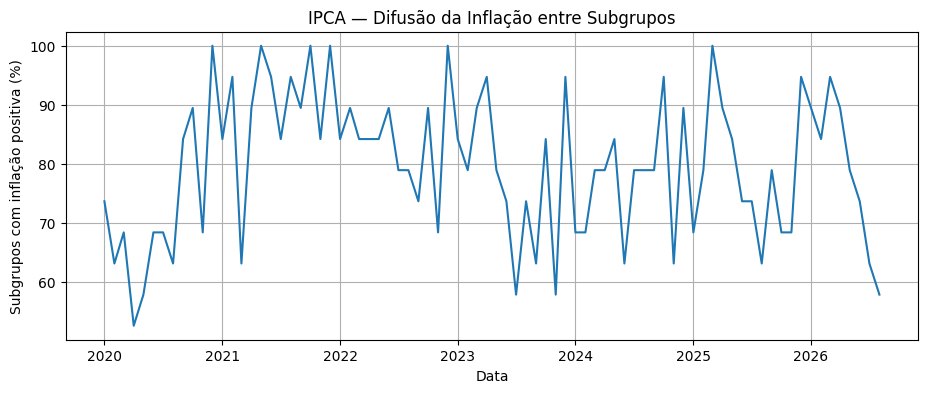

In [122]:
difusao_10a = (
    difusao_subgrupos[
        difusao_subgrupos.index
        >= data_inicio_10a
    ]
)

plt.figure(figsize=(11, 4))

plt.plot(
    difusao_10a.index,
    difusao_10a["difusao"] * 100,
)

plt.title(
    "IPCA — Difusão da Inflação entre Subgrupos"
)

plt.xlabel("Data")
plt.ylabel("Subgrupos com inflação positiva (%)")
plt.grid(True)

plt.show()

### 37. Interpretação da difusão

A combinação entre inflação agregada, impacto e difusão pode fornecer
diagnósticos bastante diferentes.

* **Inflação alta e difusão alta**

```text
muitos componentes subindo
           +
      IPCA elevado
           |
           v
  inflação disseminada
```

* **Inflação alta e difusão baixa**

```text
poucos componentes com movimentos fortes
                +
           IPCA elevado
                |
                v
      inflação concentrada
```

